In [3]:
import pandas as pd

model_df = pd.read_csv(
    "../data/processed/model_data_classification.csv"
)

model_df.head()

,obs_id,year,month,day,date,latitude,longitude,zon_winds,mer_winds,humidity,air_temp,ss_temp,site_id,use_for_climatology,split,clim_sst,ssta,current_class,target_class,label_date
0,166965,91,8,11,1991-08-11,-7.99,164.97,-6.1,-2.4,86.3,NaN,29.00,SITE_001,True,train,28.561395,0.438605,neutral,neutral,1991-11-11
1,166966,91,8,12,1991-08-12,-8.00,164.98,-2.6,-0.4,85.5,NaN,28.89,SITE_001,True,train,28.561395,0.328605,neutral,neutral,1991-11-12
2,166967,91,8,13,1991-08-13,-7.98,164.98,-3.2,-1.9,81.6,NaN,29.20,SITE_001,True,train,28.561395,0.638605,weak_el_nino,neutral,1991-11-13
3,166968,91,8,14,1991-08-14,-7.98,164.98,-1.1,2.3,80.1,NaN,29.27,SITE_001,True,train,28.561395,0.708605,weak_el_nino,neutral,1991-11-14
4,166969,91,8,15,1991-08-15,-7.99,164.98,-3.3,1.4,78.5,NaN,29.26,SITE_001,True,train,28.561395,0.698605,weak_el_nino,weak_la_nina,1991-11-15


In [4]:
features = [
    "month",
    "latitude",
    "longitude",
    "zon_winds",
    "mer_winds",
    "humidity",
    "air_temp",
    "ss_temp",
]

train = model_df[model_df["split"] == "train"].copy()
val = model_df[model_df["split"] == "validation"].copy()

X_train = train[features]
y_train = train["target_class"]

X_val = val[features]
y_val = val["target_class"]

In [5]:
from lightgbm import LGBMClassifier
model = LGBMClassifier(
    objective="multiclass",
    random_state=42,
    verbosity=-1,
    num_leaves=31,
)

model.fit(X_train, y_train)

,objective,'multiclass'
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,class_weight,None
,min_split_gain,0.0


In [6]:
%pip install scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
from sklearn.metrics import f1_score, classification_report

val_predictions = model.predict(X_val)

print("Macro F1:", f1_score(y_val, val_predictions, average="macro"))
print(classification_report(y_val, val_predictions, zero_division=0))

pd.DataFrame({
    "actual": y_val.to_numpy(),
    "predicted": val_predictions,
}).head(10)

Macro F1: 0.07713537625679626
                     precision    recall  f1-score   support

   moderate_el_nino       0.03      0.01      0.02       836
   moderate_la_nina       0.34      0.01      0.02      4268
            neutral       0.42      0.97      0.59     13598
     strong_el_nino       0.00      0.00      0.00       106
     strong_la_nina       0.07      0.00      0.01      2158
very_strong_el_nino       0.00      0.00      0.00        19
very_strong_la_nina       0.38      0.02      0.03      1779
       weak_el_nino       0.04      0.01      0.01      3357
       weak_la_nina       0.18      0.01      0.02      6978

           accuracy                           0.41     33099
          macro avg       0.16      0.11      0.08     33099
       weighted avg       0.28      0.41      0.25     33099



,actual,predicted
0,neutral,neutral
1,neutral,neutral
2,neutral,neutral
3,neutral,neutral
4,neutral,neutral
5,neutral,neutral
6,neutral,neutral
7,neutral,neutral
8,neutral,neutral
9,neutral,neutral


### How parameters affect validation macro F1

Each plot changes one parameter while keeping the others at the trained model's settings. Edit `parameter_values` to try different values, then rerun this cell. The dashed line is the current model's validation macro F1. Use a separate test set for the final unbiased evaluation after choosing parameters.

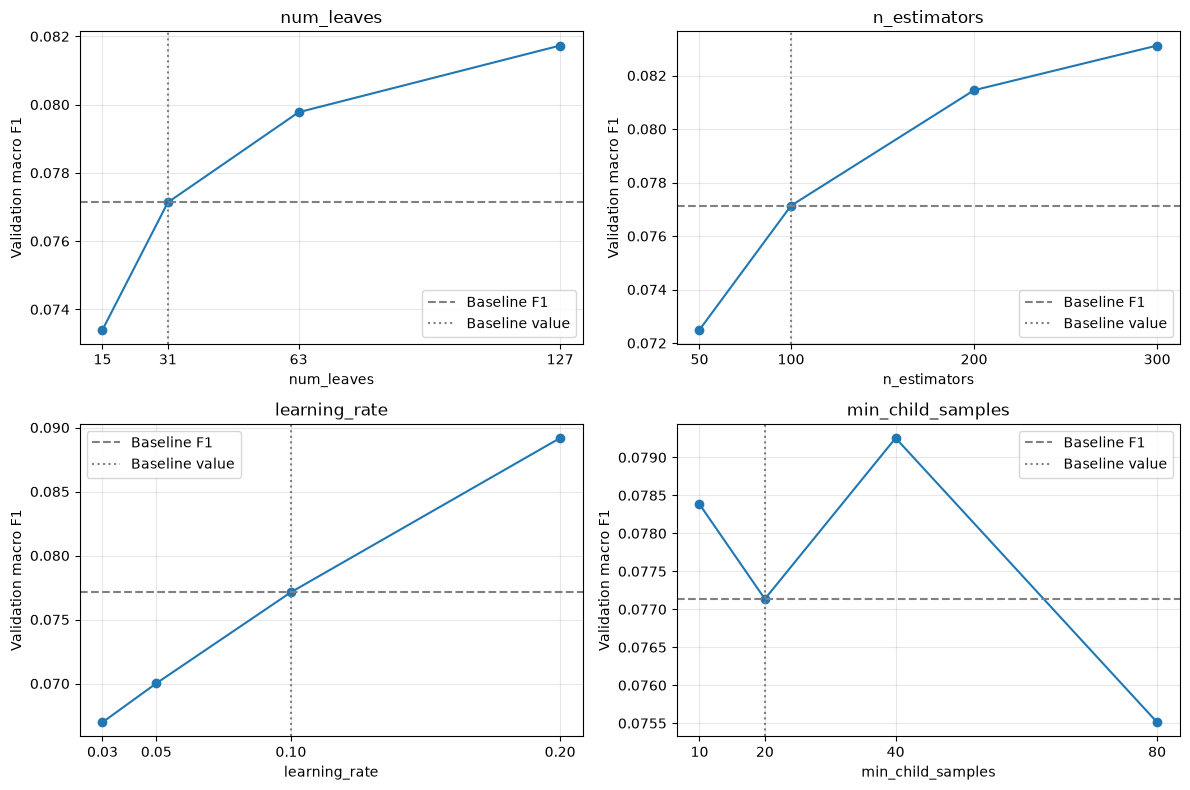

,parameter,value,macro_f1
0,num_leaves,15.00,0.073403
1,num_leaves,31.00,0.077135
2,num_leaves,63.00,0.079777
3,num_leaves,127.00,0.081730
4,n_estimators,50.00,0.072497
5,n_estimators,100.00,0.077135
6,n_estimators,200.00,0.081451
7,n_estimators,300.00,0.083120
8,learning_rate,0.03,0.066973
9,learning_rate,0.05,0.070017


In [8]:
import matplotlib.pyplot as plt

# Include the current value of each parameter so the baseline appears on every plot.
parameter_values = {
    "num_leaves": [15, 31, 63, 127],
    "n_estimators": [50, 100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "min_child_samples": [10, 20, 40, 80],
}

baseline_params = model.get_params()
baseline_f1 = f1_score(y_val, model.predict(X_val), average="macro", zero_division=0)
rows = []

for parameter, values in parameter_values.items():
    for value in values:
        if value == baseline_params[parameter]:
            score = baseline_f1
        else:
            candidate = LGBMClassifier(**{**baseline_params, parameter: value})
            candidate.fit(X_train, y_train)
            predictions = candidate.predict(X_val)
            score = f1_score(y_val, predictions, average="macro", zero_division=0)
        rows.append({"parameter": parameter, "value": value, "macro_f1": score})

results_df = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (parameter, values) in zip(axes.flat, parameter_values.items()):
    subset = results_df[results_df["parameter"] == parameter].sort_values("value")
    ax.plot(subset["value"], subset["macro_f1"], marker="o")
    ax.axhline(baseline_f1, color="gray", linestyle="--", label="Baseline F1")
    ax.axvline(baseline_params[parameter], color="gray", linestyle=":", label="Baseline value")
    ax.set_xticks(values)
    ax.set_xlabel(parameter)
    ax.set_ylabel("Validation macro F1")
    ax.set_title(parameter)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

results_df